## Imports

In [60]:
%load_ext autoreload
%autoreload 2

The autoreload extension is already loaded. To reload it, use:
  %reload_ext autoreload


In [61]:
import sys
from pathlib import Path

# Add parent directory to path to access src module
sys.path.insert(0, str(Path.cwd().parent))

import torch
import numpy as np
import matplotlib.pyplot as plt
import pandas as pd

import warnings
warnings.filterwarnings("ignore", category=DeprecationWarning)

np.random.seed(2025)

from ipywidgets import interact, IntSlider
import matplotlib.patches as patches

from src.tshred.TSHRED import TSHRED, fit
from src.processdata import TimeSeriesDataset, MaskedTimeSeriesDataset, Padding, PaddingMask
from src.utils import dim_reduction, mse, mre, mae, rmse, num2p, num2n


## **Double gyre flow**

The double gyre flow is a time-dependent model for two counter-rotating vortices (gyres) in a rectangular domain. When time is introduced via a periodic perturbation, the central dividing line between the two gyres oscillates left and right, creating a time-varying velocity field that can lead to chaotic particle trajectories. The velocity field $\mathbf{v} = [u, v]^T$ in the domain $[0, L_x] \times [0, L_y]$ and in the time interval $[0, T]$ is given by

$$
\begin{align}
u(x, y, t) &= -\pi I \sin\left( \pi f(x, t) \right) \cos\left( \pi y \right)
\\
v(x, y, t) &= \pi I \cos\left( \pi f(x, t) \right) \sin\left( \pi y \right) \frac{\partial f}{\partial x}
\end{align}
$$

\
where $I$ is the intensity parameter, $f(x, t) = \epsilon \sin(\omega t) x^2 + (1 - 2\epsilon \sin(\omega t)) x $, $\epsilon$ and $\omega$ are the perturbation amplitude and the frequency of the oscillation, respectively.

## Solver

In [62]:
# DEFINE THE SYSTEM SOLVER

def double_gyre_flow(amplitude, frequency, x, y, t):
    '''
    Solve the double gyre flow problem

    Inputs
        amplitude                   (`float`)
        frequency                   (`float`)
        horizontal discretization   (`np.array[float]`, shape: (ny,))
        vertical discretization     (`np.array[float]`, shape: (nx,))
        time vector                 (`np.array[float]`, shape: (ntimes,))

    Output
        horizontal velocity matrix  (`np.array[float]`, shape: (ntimes, nx * ny)
        vertical velocity matrix    (`np.array[float]`, shape: (ntimes, nx * ny)
    '''

    xgrid, ygrid = np.meshgrid(x, y)         # spatial grid

    u = np.zeros((len(t), len(x), len(y)))   # horizontal velocity
    v = np.zeros((len(t), len(x), len(y)))   # vertical velocity

    intensity = 0.1   # intensity parameter

    f = lambda x,t: amplitude * np.sin(frequency * t) * x**2 + x - 2 * amplitude * np.sin(frequency * t) * x

    # compute solution
    for i in range(len(t)):
      u[i] = (-np.pi * intensity * np.sin(np.pi * f(xgrid, t[i])) * np.cos(np.pi * ygrid)).T
      v[i] = (np.pi * intensity * np.cos(np.pi * f(xgrid, t[i])) * np.sin(np.pi * ygrid) * (2 * amplitude * np.sin(frequency * t[i]) * xgrid + 1.0 - 2 * amplitude * np.sin(frequency * t[i]))).T

    return u, v

In [63]:
# DATA GENERATION

amplitude_range = np.array([0.0, 0.5])
frequency_range = np.array([0.5, 2*np.pi])

# spatial discretization
nx = 50
ny = 25
Lx = 2.0
Ly = 1.0
x = np.linspace(0, Lx, nx)
y = np.linspace(0, Ly, ny)
nstate = len(x) * len(y)

# temporal discretization
dt = 0.1
T = 10.0
t = np.arange(0, T + dt, dt)
ntimes = len(t)

# training data generation
ntrajectories = 100
U = np.zeros((ntrajectories, ntimes, nx, ny))
V = np.zeros((ntrajectories, ntimes, nx, ny))

for i in range(ntrajectories):
  amplitude = (amplitude_range[1] - amplitude_range[0]) * np.random.rand() + amplitude_range[0]
  frequency = (frequency_range[1] - frequency_range[0]) * np.random.rand() + frequency_range[0]
  U[i], V[i] = double_gyre_flow(amplitude, frequency, x, y, t)

# VORTICITY CALCULATION
def vorticity(u, v):
    dx = Lx / nx
    dy = Ly / ny
    du_dy = np.gradient(u, dy, axis = 1)
    dv_dx = np.gradient(v, dx, axis = 0)
    return dv_dx - du_dy

In [64]:
# DATA VISUALIZATION

def plot_data(which_trajectory, which_time):

    offset = 0.1

    plt.figure(figsize = (10,5))
    plt.contourf(x, y, vorticity(U[which_trajectory, which_time], V[which_trajectory, which_time]).T, cmap = 'seismic', levels = 100)
    plt.streamplot(x, y, U[which_trajectory, which_time].T, V[which_trajectory, which_time].T, color='black', linewidth = 1, density = 1)
    plt.axis('off')
    plt.axis([0 - offset, Lx + offset, 0 - offset, Ly + offset])
    plt.title(f'Trajectory {which_trajectory} at time t = {round(t[which_time], 3)}')
    plt.grid(True)
    plt.gca().add_patch(patches.Rectangle((0, 0), Lx, Ly, linewidth = 5, edgecolor = 'black', facecolor = 'none'))

interact(
    plot_data, 
    which_trajectory = IntSlider(min = 0, max = ntrajectories - 1, step = 1, description='Trajectory'), 
    which_time = IntSlider(min = 0, max = ntimes - 1, step = 1, description='Time step')
);

interactive(children=(IntSlider(value=0, description='Trajectory', max=99), IntSlider(value=0, description='Ti…

In [65]:
# TORCH CONVERSION

U = torch.from_numpy(U.reshape(ntrajectories, ntimes, nstate))
V = torch.from_numpy(V.reshape(ntrajectories, ntimes, nstate))

print(f'U shape: {U.shape} \nV shape: {V.shape}')

U shape: torch.Size([100, 101, 1250]) 
V shape: torch.Size([100, 101, 1250])


## Broken sensors simulations

In [66]:
# EXTRACT SENSORS DATA

nsensors = 3
short_broken = 1
long_broken = 1

idx_sensors = np.random.choice(nstate, size = nsensors, replace = False)
idx_short_broken_s = idx_sensors[0:short_broken]
idx_long_broken_s = idx_sensors[short_broken:short_broken+long_broken]

print("Available sensors:\t", idx_sensors)
print("short broken sensors:\t", idx_short_broken_s)
print("long broken sensors:\t", idx_long_broken_s)

sensors_data = U[:,:,idx_sensors]

idx_sensors_x, idx_sensors_y = np.unravel_index(idx_sensors, (nx, ny))
sensors_coordinates = np.vstack((x[idx_sensors_x], y[idx_sensors_y]))

Available sensors:	 [690 587 929]
short broken sensors:	 [690]
long broken sensors:	 [587]


In [67]:
# SHORT BROKEN SIMULATION

# broken = bernoulli distribution
p_short_broken = 0.2
for idx in idx_short_broken_s:
    local_idx = np.where(idx_sensors == idx)[0][0]

    mask_train = torch.rand(sensors_data[:, :, local_idx].shape) < p_short_broken
    print("simulation of short broken sensor idx\t", idx, "\twith probability", p_short_broken)

    sensors_data[:, :, local_idx][mask_train] = float('nan')


# LONG BROKEN SIMULATION

#draw 2 numbers and erase in the middle
for idx in idx_long_broken_s:
    local_idx = np.where(idx_sensors == idx)[0][0]

    t1, t2 = np.random.randint(0, ntimes, size=2)
    t_start, t_end = min(t1, t2), max(t1, t2)
    if t_end - t_start < 30: # if the interval is too short, make it longer
        t_end = min(t_start + 38, ntimes-1)
    print("simulation of long broken sensor idx\t", idx, "\tfrom time step", t_start, "to time step", t_end)

    sensors_data[:, t_start:t_end + 1, local_idx] = float('nan')

simulation of short broken sensor idx	 690 	with probability 0.2
simulation of long broken sensor idx	 587 	from time step 42 to time step 80


In [68]:
# PLOT DATA AVAILABILITY

def plot_data_availability(sensor_data, title_prefix, trajectory=0, sensor_labels=None):
    traj_idx = min(trajectory, sensor_data.shape[0] - 1)
    availability = (~torch.isnan(sensor_data[traj_idx])).to(torch.float32).cpu().numpy()
    time = np.arange(availability.shape[0])
    nsensors_plot = availability.shape[1]

    if sensor_labels is None:
        sensor_labels = np.arange(nsensors_plot)
    sensor_labels = np.asarray(sensor_labels)

    if sensor_labels.shape[0] != nsensors_plot:
        raise ValueError("sensor_labels length must match number of sensor columns")

    fig_height = max(3.0, 0.7 * nsensors_plot)
    _, ax = plt.subplots(1, 1, figsize=(14, fig_height))

    for sensor_idx in range(nsensors_plot):
        line = np.where(availability[:, sensor_idx] > 0.5, sensor_idx + 1.0, np.nan)
        ax.plot(time, line, linewidth=4, solid_capstyle="butt", label=f"S{sensor_labels[sensor_idx]}")

    ax.set_xlabel("Time step")
    ax.set_ylabel("Sensor")
    ax.set_yticks(np.arange(1, nsensors_plot + 1))
    ax.set_yticklabels([f"S{label}" for label in sensor_labels])
    ax.set_ylim(0.5, nsensors_plot + 0.5)
    ax.grid(True, axis="x", alpha=0.25)
    ax.legend(loc="center left", bbox_to_anchor=(1.01, 0.5), title="Sensors")

    plt.title(f"{title_prefix} - Trajectory {traj_idx}")
    plt.tight_layout()
    plt.show()

In [69]:
def plot_train_data_availability(trajectory=0):
    plot_data_availability(
        sensors_data,
        "Train availability",
        trajectory,
        sensor_labels=np.arange(sensors_data.shape[2])
    )

interact(
    plot_train_data_availability,
    trajectory=IntSlider(min=0, max=sensors_data.shape[0] - 1, step=1, value=0, description="Trajectory"),
);

interactive(children=(IntSlider(value=0, description='Trajectory', max=99), Output()), _dom_classes=('widget-i…

In [70]:
print("U shape: \t", U.shape)
print("V shape: \t", V.shape)
print("input shape: \t", sensors_data.shape)

U shape: 	 torch.Size([100, 101, 1250])
V shape: 	 torch.Size([100, 101, 1250])
input shape: 	 torch.Size([100, 101, 3])


## TRAIN VAL TEST split

In [71]:
## Splitting the data into train, valid and test sets

#split the sizes
train_size = int(0.8 * ntrajectories)
val_size = int(0.1 * ntrajectories)
test_size = ntrajectories - train_size - val_size
print(f"Train size: {train_size} \nValidation size: {val_size} \nTest size: {test_size}")

#shuffle the data
shuffle_indices = torch.randperm(ntrajectories)
U = U[shuffle_indices]
V = V[shuffle_indices]
sensors_data = sensors_data[shuffle_indices]

#split the data
U_train, U_val, U_test = torch.split(U, [train_size, val_size, test_size], dim=0)
V_train, V_val, V_test = torch.split(V, [train_size, val_size, test_size], dim=0)
input_train, input_val, input_test = torch.split(sensors_data, [train_size, val_size, test_size], dim=0)

#print 
print(f"\nU_train shape:\t{U_train.shape} \nV_train shape:\t{V_train.shape} \ninput_train shape:\t{input_train.shape}")
print(f"\nU_val shape:\t{U_val.shape} \nV_val shape:\t{V_val.shape} \ninput_val shape:\t{input_val.shape}")
print(f"\nU_test shape:\t{U_test.shape} \nV_test shape:\t{V_test.shape} \ninput_test shape:\t{input_test.shape}")


Train size: 80 
Validation size: 10 
Test size: 10

U_train shape:	torch.Size([80, 101, 1250]) 
V_train shape:	torch.Size([80, 101, 1250]) 
input_train shape:	torch.Size([80, 101, 3])

U_val shape:	torch.Size([10, 101, 1250]) 
V_val shape:	torch.Size([10, 101, 1250]) 
input_val shape:	torch.Size([10, 101, 3])

U_test shape:	torch.Size([10, 101, 1250]) 
V_test shape:	torch.Size([10, 101, 1250]) 
input_test shape:	torch.Size([10, 101, 3])


## POD based reduction

Residual energy is equal to  7.660639569093903e-07



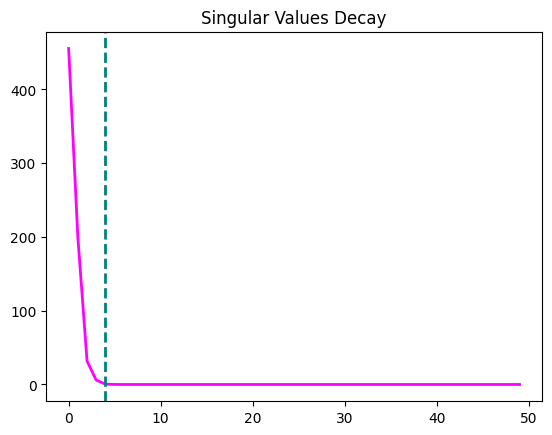

Residual energy is equal to  6.4586399937117025e-06



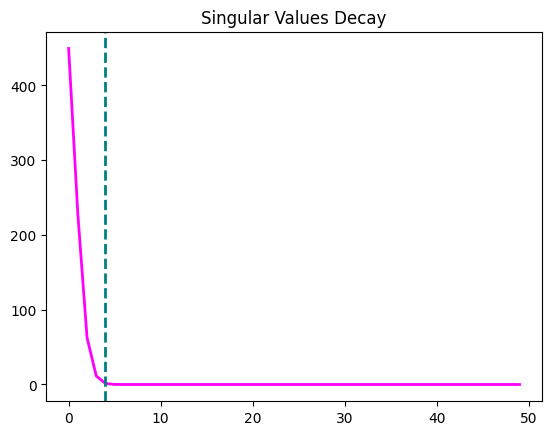

In [72]:
POD_modes = 4

## Dimensionality reduction with POD

U_train, U_val, U_test, U_train_proj, U_val_proj, U_test_proj, V1_POD = dim_reduction(U_train, U_val, U_test, POD_modes)
V_train, V_val, V_test, V_train_proj, V_val_proj, V_test_proj, V2_POD = dim_reduction(V_train, V_val, V_test, POD_modes)

In [73]:
print(f'U_train shape:\t\t{U_train.shape}')
print(f'U_train_proj shape:\t{U_train_proj.shape}')
print(f'V_train shape:\t\t{V_train.shape}')
print(f'V_train_proj shape:\t{V_train_proj.shape}')

U_train shape:		torch.Size([80, 101, 1250])
U_train_proj shape:	torch.Size([80, 101, 4])
V_train shape:		torch.Size([80, 101, 1250])
V_train_proj shape:	torch.Size([80, 101, 4])


In [74]:
ERRORS = []

## **Idea 0: Only Availabe Sensors**

In [75]:
interact(
    plot_train_data_availability,
    trajectory=IntSlider(min=0, max=sensors_data.shape[0] - 1, step=1, value=0, description="Trajectory"),
);

interactive(children=(IntSlider(value=0, description='Trajectory', max=99), Output()), _dom_classes=('widget-i…

In [76]:
## REMOVE SENSORS NOT ALWAYS AVAILABLE

# Keep only sensors that are always available in all splits.
always_available_mask = (
    ~torch.isnan(input_train).any(dim=(0, 1)) & 
    ~torch.isnan(input_val).any(dim=(0, 1)) & 
    ~torch.isnan(input_test).any(dim=(0, 1))
)

# Get indices of sensors to keep and remove
keep_sensor_idx = np.where(always_available_mask.cpu().numpy())[0]
removed_sensor_idx = np.setdiff1d(np.arange(nsensors), keep_sensor_idx)
navailable_sensors = len(keep_sensor_idx)

# Clean the input data by keeping only the always available sensors
cleaned_input_train = input_train[:, :, keep_sensor_idx]
cleaned_input_val = input_val[:, :, keep_sensor_idx]
cleaned_input_test = input_test[:, :, keep_sensor_idx]

print("Kept local sensor columns:\t", keep_sensor_idx)
print("Removed local sensor columns:\t", removed_sensor_idx)
print("Number of available sensors after cleaning:\t", navailable_sensors)

# PLOT CLEANED DATA AVAILABILITY (TRAIN ONLY)
def plot_cleaned_train_data_availability(trajectory=0):
    plot_data_availability(
        cleaned_input_train,
        "Cleaned Train availability",
        trajectory,
        sensor_labels=keep_sensor_idx
    )

interact(
    plot_cleaned_train_data_availability,
    trajectory=IntSlider(min=0, max=cleaned_input_train.shape[0] - 1, step=1, value=0, description="Trajectory"),
);


Kept local sensor columns:	 [2]
Removed local sensor columns:	 [0 1]
Number of available sensors after cleaning:	 1


interactive(children=(IntSlider(value=0, description='Trajectory', max=79), Output()), _dom_classes=('widget-i…

In [77]:
# BUILD TRAIN, VALIDATION AND TEST DATASETS WITH PADDING

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

lag = 25

train_data_in = Padding(cleaned_input_train, lag).to(device)
valid_data_in = Padding(cleaned_input_val, lag).to(device)
test_data_in = Padding(cleaned_input_test, lag).to(device)

train_data_out = Padding(torch.cat((U_train_proj, V_train_proj), 2), 1).squeeze(1).to(device)
valid_data_out = Padding(torch.cat((U_val_proj, V_val_proj), 2), 1).squeeze(1).to(device)
test_data_out = Padding(torch.cat((U_test_proj, V_test_proj), 2), 1).squeeze(1).to(device)

train_dataset = TimeSeriesDataset(train_data_in, train_data_out)
valid_dataset = TimeSeriesDataset(valid_data_in, valid_data_out)
test_dataset = TimeSeriesDataset(test_data_in, test_data_out)

print(f"Train dataset shape: \n{train_data_in.shape} -> {train_data_out.shape}")
print(f"Validation dataset shape: \n{valid_data_in.shape} -> {valid_data_out.shape}")
print(f"Test dataset shape: \n{test_data_in.shape} -> {test_data_out.shape}")


Using device: cpu
Train dataset shape: 
torch.Size([8080, 25, 1]) -> torch.Size([8080, 8])
Validation dataset shape: 
torch.Size([1010, 25, 1]) -> torch.Size([1010, 8])
Test dataset shape: 
torch.Size([1010, 25, 1]) -> torch.Size([1010, 8])


In [78]:
xlstm_types = ['sLSTM', 'mLSTM']
idea0_models = {}

for xlstm_type in xlstm_types:
    model_args = dict(
        # Encoder
        encoder         = "xlstm",
        encoder_depth   = 1,
        input_size      = navailable_sensors,   # input feature dim (one value per sensor)
        hidden_size     = 32,
        xlstm_type      = xlstm_type,

        # Decoder
        decoder         = "cnn",
        decoder_depth   = 1,
        output_size     = 2 * POD_modes,        # U + V POD coefficients

        # Shared
        dropout         = 0.0,
        device          = device,
    )
    idea0_models[xlstm_type] = TSHRED(args=model_args)
    print(f"Built xLSTM-{xlstm_type} model")


Built xLSTM-sLSTM model
Built xLSTM-mLSTM model


In [79]:
idea0_errors = {}

for xlstm_type in xlstm_types:
    print(f"\nTraining xLSTM-{xlstm_type} — Only Available Sensors...")
    tr_err, val_err = fit(
        idea0_models[xlstm_type], train_dataset, valid_dataset,
        batch_size=64, epochs=300, lr=1e-3, verbose=True, patience=40
    )
    idea0_errors[xlstm_type] = {'train': tr_err, 'valid': val_err}

# Use mLSTM as default model for reconstruction
tshred       = idea0_models['mLSTM']
train_errors = idea0_errors['mLSTM']['train']
valid_errors = idea0_errors['mLSTM']['valid']



Training xLSTM-sLSTM — Only Available Sensors...


Training: 100%|██████████| 300/300 [06:13<00:00,  1.25s/it, Train Error=9.849%, Val Error=10.097%, Patience=5, Best Val Error=8.860%, LR=5.00e-04]   


Training Complete (300 epochs)

Training xLSTM-mLSTM — Only Available Sensors...


Training:  29%|██▉       | 88/300 [03:56<09:28,  2.68s/it, Train Error=34.263%, Val Error=27.940%, Patience=39, Best Val Error=27.706%, LR=5.00e-04]

Early stopping at epoch 89


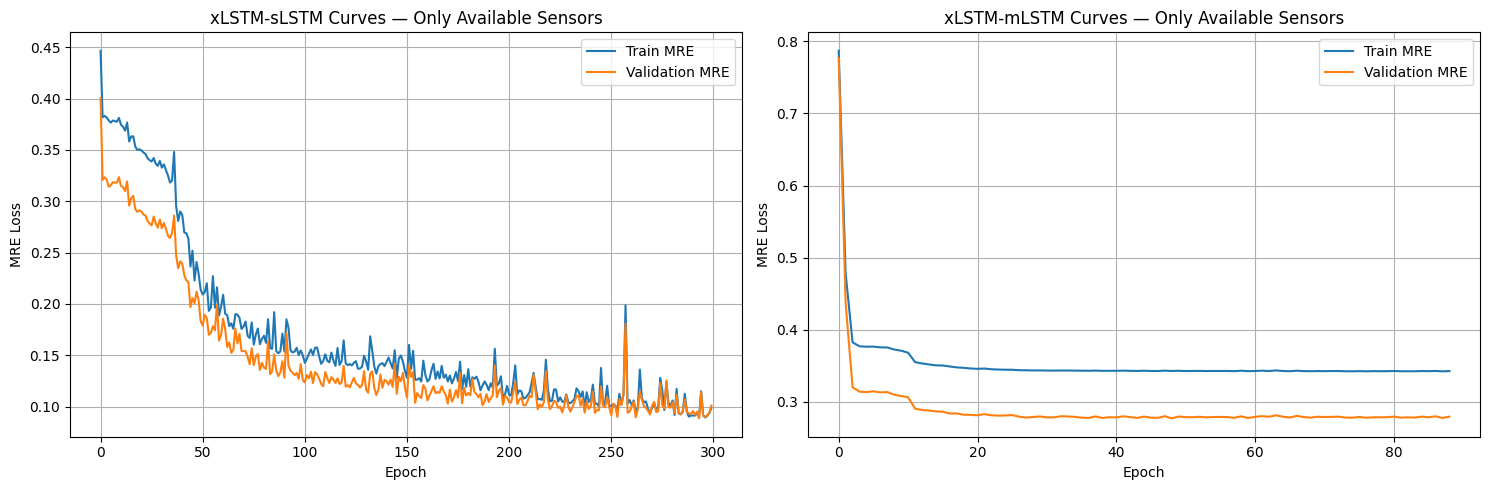

In [80]:
# PLOT TRAINING CURVES

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, xlstm_type in zip(axes, xlstm_types):
    ax.plot(idea0_errors[xlstm_type]['train'], label='Train MRE')
    ax.plot(idea0_errors[xlstm_type]['valid'], label='Validation MRE')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MRE Loss')
    ax.set_title(f'xLSTM-{xlstm_type} Curves — Only Available Sensors')
    ax.legend()
    ax.grid()
plt.tight_layout()
plt.show()


In [81]:
tshred.freeze()

UVtest_hat_grud = tshred(test_data_in).to(torch.float64)

Utest_hat = UVtest_hat_grud[:, :POD_modes] @ V1_POD[:POD_modes, :]
Utest_hat = Utest_hat.reshape(test_size, ntimes, nx, ny)
Utest = U_test.reshape(test_size, ntimes, nx, ny)

Vtest_hat = UVtest_hat_grud[:, POD_modes:] @ V2_POD[:POD_modes, :]
Vtest_hat = Vtest_hat.reshape(test_size, ntimes, nx, ny)
Vtest = V_test.reshape(test_size, ntimes, nx, ny)

def plot_shred_reconstruction(which_test_trajectory, which_time):
    offset = 0.1

    fig, axes = plt.subplots(1, 2, figsize=(20, 5))

    for ax, field_u, field_v, title in zip(
        axes,
        [Utest[which_test_trajectory, which_time],     Utest_hat[which_test_trajectory, which_time]],
        [Vtest[which_test_trajectory, which_time],     Vtest_hat[which_test_trajectory, which_time]],
        [f'Test case {which_test_trajectory} at t = {round(t[which_time], 3)}',
         f'xLSTM-mLSTM reconstruction at t = {round(t[which_time], 3)}']
    ):
        ax.contourf(x, y, vorticity(field_u, field_v).T, cmap='seismic', levels=100)
        ax.streamplot(x, y, field_u.T, field_v.T, color='black', linewidth=1, density=1)
        ax.axis('off')
        ax.axis([0 - offset, Lx + offset, 0 - offset, Ly + offset])
        ax.set_title(title)
        ax.add_patch(patches.Rectangle((0, 0), Lx, Ly, linewidth=5, edgecolor='black', facecolor='none'))
        for k in range(navailable_sensors):
            ax.plot(
                sensors_coordinates[0, keep_sensor_idx[k]], sensors_coordinates[1, keep_sensor_idx[k]],
                'o', mfc='magenta', mec='black', ms=12, mew=2.0,
                label='Sensor' if k == 0 else None
            )
        ax.legend(loc='upper right', frameon=True)

    plt.tight_layout()
    plt.show()

interact(
    plot_shred_reconstruction,
    which_test_trajectory=IntSlider(value=0, min=0, max=test_size - 1, description='Test case'),
    which_time=IntSlider(min=0, max=ntimes - 1, step=1, description='Time step')
);


interactive(children=(IntSlider(value=0, description='Test case', max=9), IntSlider(value=0, description='Time…

In [82]:
## COMPUTE TEST ERRORS FOR BOTH xLSTM VARIANTS

Utest_flat = U_test.reshape(test_size * ntimes, -1).to(torch.float64)
Vtest_flat = V_test.reshape(test_size * ntimes, -1).to(torch.float64)

for xlstm_type in xlstm_types:
    idea0_models[xlstm_type].freeze()
    UVtest_hat = idea0_models[xlstm_type](test_data_in).to(torch.float64)

    Utest_hat_flat = (UVtest_hat[:, :POD_modes] @ V1_POD[:POD_modes, :]).reshape(test_size * ntimes, -1)
    Vtest_hat_flat = (UVtest_hat[:, POD_modes:] @ V2_POD[:POD_modes, :]).reshape(test_size * ntimes, -1)

    combined_rmse = (rmse(Utest_flat, Utest_hat_flat) + rmse(Vtest_flat, Vtest_hat_flat)) / 2
    combined_mae  = (mae(Utest_flat,  Utest_hat_flat) + mae(Vtest_flat,  Vtest_hat_flat)) / 2
    combined_mre  = (mre(Utest_flat,  Utest_hat_flat) + mre(Vtest_flat,  Vtest_hat_flat)) / 2

    best_epoch = idea0_errors[xlstm_type]['valid'].argmin()
    ERRORS.append({
        'model':     f'(xL-{xlstm_type}) Only available sensors',
        'train-mre': num2p(idea0_errors[xlstm_type]['train'][best_epoch]),
        'val-mre':   num2p(idea0_errors[xlstm_type]['valid'][best_epoch]),
        'test-mre':  num2p(combined_mre),
        'test-rmse': num2n(combined_rmse),
        'test-mae':  num2n(combined_mae),
    })


In [83]:
dataframe_errors = pd.DataFrame(ERRORS)
print(dataframe_errors)


                               model train-mre  val-mre test-mre test-rmse  \
0  (xL-sLSTM) Only available sensors    8.995%   8.860%  10.921%    1.0239   
1  (xL-mLSTM) Only available sensors   34.277%  27.706%  23.897%    1.6898   

  test-mae  
0   0.0130  
1   0.0284  


## **Idea 1.A: Median Imputer**

In [84]:
interact(
    plot_train_data_availability,
    trajectory=IntSlider(min=0, max=sensors_data.shape[0] - 1, step=1, value=0, description="Trajectory"),
);

interactive(children=(IntSlider(value=0, description='Trajectory', max=99), Output()), _dom_classes=('widget-i…

In [85]:
# DEFINE A MEDIAN IMPUTER FOR TIMESERIES DATA

def get_train_medians(X_train):
    
    # Calculate median across Batch (axis 0) and Time (axis 1) dimensions
    # to obtain a specific median value for each individual sensor.
    X_reshaped = X_train.reshape(-1, X_train.shape[2])  # Shape: (batch*time, sensors)
    medians = torch.nanmedian(X_reshaped, dim=0).values
    
    # Handle edge case: if a sensor is entirely NaN in the training set,
    # fill its median with 0.0 to prevent propagating NaNs during transform.
    medians = torch.nan_to_num(medians, nan=0.0)
    
    return medians

def apply_imputation(X, medians):
    
    # Create a copy to prevent overwriting the original input array
    X_imputed = X.clone()
    
    # Locate the indices where values are NaN
    nan_indices = torch.where(torch.isnan(X_imputed))
    
    # Replace NaNs by mapping the sensor index (nan_indices[2])
    # to its corresponding pre-calculated median value.
    X_imputed[nan_indices] = medians[nan_indices[2]]
    
    return X_imputed

In [86]:
# APPLY MEDIAN IMPUTATION TO TRAIN, VALIDATION AND TEST DATA

medians = get_train_medians(input_train)

imputed_input_train = apply_imputation(input_train, medians)
imputed_input_val   = apply_imputation(input_val,   medians)
imputed_input_test  = apply_imputation(input_test,  medians)

In [87]:
def plot_imputed_train_data_availability(trajectory=0):
    plot_data_availability(
        imputed_input_train,
        "Train availability (Median imputed)",
        trajectory,
        sensor_labels=np.arange(imputed_input_train.shape[2])
    )

interact(
    plot_imputed_train_data_availability,
    trajectory=IntSlider(min=0, max=imputed_input_train.shape[0] - 1, step=1, value=0, description="Trajectory"),
);

interactive(children=(IntSlider(value=0, description='Trajectory', max=79), Output()), _dom_classes=('widget-i…

In [88]:
# BUILD TRAIN, VALIDATION AND TEST DATASETS WITH PADDING

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

lag = 25

train_data_in = Padding(imputed_input_train, lag).to(device)
valid_data_in = Padding(imputed_input_val,   lag).to(device)
test_data_in  = Padding(imputed_input_test,  lag).to(device)

train_data_out = Padding(torch.cat((U_train_proj, V_train_proj), 2), 1).squeeze(1).to(device)
valid_data_out = Padding(torch.cat((U_val_proj,   V_val_proj),   2), 1).squeeze(1).to(device)
test_data_out  = Padding(torch.cat((U_test_proj,  V_test_proj),  2), 1).squeeze(1).to(device)

train_dataset = TimeSeriesDataset(train_data_in, train_data_out)
valid_dataset = TimeSeriesDataset(valid_data_in, valid_data_out)
test_dataset  = TimeSeriesDataset(test_data_in,  test_data_out)

print(f"Train dataset shape: \n{train_data_in.shape} -> {train_data_out.shape}")
print(f"Validation dataset shape: \n{valid_data_in.shape} -> {valid_data_out.shape}")
print(f"Test dataset shape: \n{test_data_in.shape} -> {test_data_out.shape}")

Using device: cpu
Train dataset shape: 
torch.Size([8080, 25, 3]) -> torch.Size([8080, 8])
Validation dataset shape: 
torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])
Test dataset shape: 
torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])


In [89]:
idea1a_models = {}
idea1a_errors = {}

for xlstm_type in xlstm_types:
    model_args = dict(
        # Encoder
        encoder         = "xlstm",
        encoder_depth   = 1,
        input_size      = nsensors,     # input feature dim (all sensors after imputation)
        hidden_size     = 32,
        xlstm_type      = xlstm_type,

        # Decoder
        decoder         = "cnn",
        decoder_depth   = 1,
        output_size     = 2 * POD_modes,

        # Shared
        dropout         = 0.0,
        device          = device,
    )
    idea1a_models[xlstm_type] = TSHRED(args=model_args)

    print(f"\nTraining xLSTM-{xlstm_type} — Median Imputation...")
    tr_err, val_err = fit(
        idea1a_models[xlstm_type], train_dataset, valid_dataset,
        batch_size=64, epochs=300, lr=1e-3, verbose=True, patience=40
    )
    idea1a_errors[xlstm_type] = {'train': tr_err, 'valid': val_err}

# Use mLSTM as default for reconstruction
tshred       = idea1a_models['mLSTM']
train_errors = idea1a_errors['mLSTM']['train']
valid_errors = idea1a_errors['mLSTM']['valid']



Training xLSTM-sLSTM — Median Imputation...


Training: 100%|██████████| 300/300 [06:20<00:00,  1.27s/it, Train Error=1.661%, Val Error=1.722%, Patience=9, Best Val Error=1.669%, LR=1.00e-03]  


Training Complete (300 epochs)

Training xLSTM-mLSTM — Median Imputation...


Training: 100%|██████████| 300/300 [14:10<00:00,  2.83s/it, Train Error=8.225%, Val Error=7.483%, Patience=12, Best Val Error=7.483%, LR=1.00e-03] 

Training Complete (300 epochs)


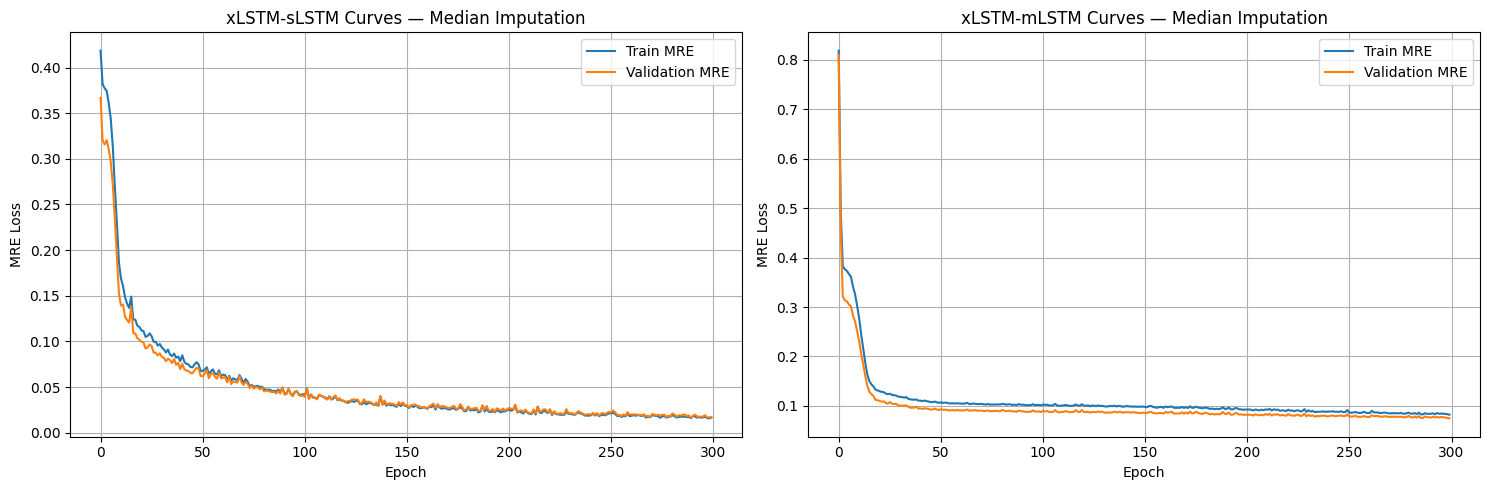

In [90]:
# PLOT TRAINING CURVES

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, xlstm_type in zip(axes, xlstm_types):
    ax.plot(idea1a_errors[xlstm_type]['train'], label='Train MRE')
    ax.plot(idea1a_errors[xlstm_type]['valid'], label='Validation MRE')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MRE Loss')
    ax.set_title(f'xLSTM-{xlstm_type} Curves — Median Imputation')
    ax.legend()
    ax.grid()
plt.tight_layout()
plt.show()


In [91]:
tshred.freeze()

UVtest_hat_grud = tshred(test_data_in).to(torch.float64)

Utest_hat = UVtest_hat_grud[:, :POD_modes] @ V1_POD[:POD_modes, :]
Utest_hat = Utest_hat.reshape(test_size, ntimes, nx, ny)
Utest = U_test.reshape(test_size, ntimes, nx, ny)

Vtest_hat = UVtest_hat_grud[:, POD_modes:] @ V2_POD[:POD_modes, :]
Vtest_hat = Vtest_hat.reshape(test_size, ntimes, nx, ny)
Vtest = V_test.reshape(test_size, ntimes, nx, ny)

def plot_tshred_reconstruction(which_test_trajectory, which_time):
    offset = 0.1

    fig, axes = plt.subplots(1, 2, figsize=(20, 5))

    for ax, field_u, field_v, title in zip(
        axes,
        [Utest[which_test_trajectory, which_time],     Utest_hat[which_test_trajectory, which_time]],
        [Vtest[which_test_trajectory, which_time],     Vtest_hat[which_test_trajectory, which_time]],
        [f'Test case {which_test_trajectory} at t = {round(t[which_time], 3)}',
         f'xLSTM-mLSTM (Median) reconstruction at t = {round(t[which_time], 3)}']
    ):
        ax.contourf(x, y, vorticity(field_u, field_v).T, cmap='seismic', levels=100)
        ax.streamplot(x, y, field_u.T, field_v.T, color='black', linewidth=1, density=1)
        ax.axis('off')
        ax.axis([0 - offset, Lx + offset, 0 - offset, Ly + offset])
        ax.set_title(title)
        ax.add_patch(patches.Rectangle((0, 0), Lx, Ly, linewidth=5, edgecolor='black', facecolor='none'))
        for k in range(nsensors):
            ax.plot(
                sensors_coordinates[0, k], sensors_coordinates[1, k],
                'o', mfc='magenta', mec='black', ms=12, mew=2.0,
                label='Sensor' if k == 0 else None
            )
        ax.legend(loc='upper right', frameon=True)

    plt.tight_layout()
    plt.show()

interact(
    plot_tshred_reconstruction,
    which_test_trajectory=IntSlider(value=0, min=0, max=test_size - 1, description='Test case'),
    which_time=IntSlider(min=0, max=ntimes - 1, step=1, description='Time step')
);

interactive(children=(IntSlider(value=0, description='Test case', max=9), IntSlider(value=0, description='Time…

In [92]:
## COMPUTE TEST ERRORS FOR BOTH xLSTM VARIANTS

Utest_flat = U_test.reshape(test_size * ntimes, -1).to(torch.float64)
Vtest_flat = V_test.reshape(test_size * ntimes, -1).to(torch.float64)

for xlstm_type in xlstm_types:
    idea1a_models[xlstm_type].freeze()
    UVtest_hat = idea1a_models[xlstm_type](test_data_in).to(torch.float64)

    Utest_hat_flat = (UVtest_hat[:, :POD_modes] @ V1_POD[:POD_modes, :]).reshape(test_size * ntimes, -1)
    Vtest_hat_flat = (UVtest_hat[:, POD_modes:] @ V2_POD[:POD_modes, :]).reshape(test_size * ntimes, -1)

    combined_rmse = (rmse(Utest_flat, Utest_hat_flat) + rmse(Vtest_flat, Vtest_hat_flat)) / 2
    combined_mae  = (mae(Utest_flat,  Utest_hat_flat) + mae(Vtest_flat,  Vtest_hat_flat)) / 2
    combined_mre  = (mre(Utest_flat,  Utest_hat_flat) + mre(Vtest_flat,  Vtest_hat_flat)) / 2

    best_epoch = idea1a_errors[xlstm_type]['valid'].argmin()
    ERRORS.append({
        'model':     f'(xL-{xlstm_type}) Median imputation',
        'train-mre': num2p(idea1a_errors[xlstm_type]['train'][best_epoch]),
        'val-mre':   num2p(idea1a_errors[xlstm_type]['valid'][best_epoch]),
        'test-mre':  num2p(combined_mre),
        'test-rmse': num2n(combined_rmse),
        'test-mae':  num2n(combined_mae),
    })


In [93]:
dataframe_errors = pd.DataFrame(ERRORS)
print(dataframe_errors)


                               model train-mre  val-mre test-mre test-rmse  \
0  (xL-sLSTM) Only available sensors    8.995%   8.860%  10.921%    1.0239   
1  (xL-mLSTM) Only available sensors   34.277%  27.706%  23.897%    1.6898   
2       (xL-sLSTM) Median imputation    1.598%   1.669%   1.740%    0.1312   
3       (xL-mLSTM) Median imputation    8.225%   7.483%   5.736%    0.4903   

  test-mae  
0   0.0130  
1   0.0284  
2   0.0020  
3   0.0068  



##  **Idea 1.B: Last value Imputer**

In [94]:
interact(
    plot_train_data_availability,
    trajectory=IntSlider(min=0, max=sensors_data.shape[0] - 1, step=1, value=0, description="Trajectory"),
);

interactive(children=(IntSlider(value=0, description='Trajectory', max=99), Output()), _dom_classes=('widget-i…

In [95]:
# DEFINE A LAST VALUE IMPUTER FOR TIMESERIES DATA

def apply_LV_imputation(X):
    
    # Create a copy to prevent overwriting the original input array
    X_imputed = X.clone()
    
    # Iterate over each sample in the batch and each sensor
    for i in range(X_imputed.shape[0]):   # Iterate over batch dimension
        for j in range(X_imputed.shape[2]):  # Iterate over sensor dimension
            
            time_series = X_imputed[i, :, j]
            nan_indices = torch.where(torch.isnan(time_series))[0]
            
            if len(nan_indices) == 0:
                continue  # No NaNs, skip to next sensor
            
            # For each NaN index, replace with the last valid value
            for idx in nan_indices:
                if idx == 0:
                    time_series[idx] = 0.0  # If the first value is NaN, replace with 0.0
                else:
                    time_series[idx] = time_series[idx - 1]  # Replace with last valid value

    return X_imputed

In [96]:
# APPLY LAST VALUE IMPUTATION TO TRAIN, VALIDATION AND TEST DATA

imputed_input_train = apply_LV_imputation(input_train)
imputed_input_val   = apply_LV_imputation(input_val)
imputed_input_test  = apply_LV_imputation(input_test)

In [97]:
def plot_lv_imputed_train_data_availability(trajectory=0):
    plot_data_availability(
        imputed_input_train,
        "Train availability (Last-value imputed)",
        trajectory,
        sensor_labels=np.arange(imputed_input_train.shape[2])
    )

interact(
    plot_lv_imputed_train_data_availability,
    trajectory=IntSlider(min=0, max=imputed_input_train.shape[0] - 1, step=1, value=0, description="Trajectory"),
);

interactive(children=(IntSlider(value=0, description='Trajectory', max=79), Output()), _dom_classes=('widget-i…

In [98]:
# BUILD TRAIN, VALIDATION AND TEST DATASETS WITH PADDING

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

lag = 25

train_data_in = Padding(imputed_input_train, lag).to(device)
valid_data_in = Padding(imputed_input_val,   lag).to(device)
test_data_in  = Padding(imputed_input_test,  lag).to(device)

train_data_out = Padding(torch.cat((U_train_proj, V_train_proj), 2), 1).squeeze(1).to(device)
valid_data_out = Padding(torch.cat((U_val_proj,   V_val_proj),   2), 1).squeeze(1).to(device)
test_data_out  = Padding(torch.cat((U_test_proj,  V_test_proj),  2), 1).squeeze(1).to(device)

train_dataset = TimeSeriesDataset(train_data_in, train_data_out)
valid_dataset = TimeSeriesDataset(valid_data_in, valid_data_out)
test_dataset  = TimeSeriesDataset(test_data_in,  test_data_out)

print(f"Train dataset shape: \n{train_data_in.shape} -> {train_data_out.shape}")
print(f"Validation dataset shape: \n{valid_data_in.shape} -> {valid_data_out.shape}")
print(f"Test dataset shape: \n{test_data_in.shape} -> {test_data_out.shape}")

Using device: cpu
Train dataset shape: 
torch.Size([8080, 25, 3]) -> torch.Size([8080, 8])
Validation dataset shape: 
torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])
Test dataset shape: 
torch.Size([1010, 25, 3]) -> torch.Size([1010, 8])


In [99]:
idea1b_models = {}
idea1b_errors = {}

for xlstm_type in xlstm_types:
    model_args = dict(
        # Encoder
        encoder         = "xlstm",
        encoder_depth   = 1,
        input_size      = nsensors,     # input feature dim (all sensors after imputation)
        hidden_size     = 32,
        xlstm_type      = xlstm_type,

        # Decoder
        decoder         = "cnn",
        decoder_depth   = 1,
        output_size     = 2 * POD_modes,

        # Shared
        dropout         = 0.0,
        device          = device,
    )
    idea1b_models[xlstm_type] = TSHRED(args=model_args)

    print(f"\nTraining xLSTM-{xlstm_type} — Last Value Imputation...")
    tr_err, val_err = fit(
        idea1b_models[xlstm_type], train_dataset, valid_dataset,
        batch_size=64, epochs=300, lr=1e-3, verbose=True, patience=40
    )
    idea1b_errors[xlstm_type] = {'train': tr_err, 'valid': val_err}

# Use mLSTM as default for reconstruction
tshred       = idea1b_models['mLSTM']
train_errors = idea1b_errors['mLSTM']['train']
valid_errors = idea1b_errors['mLSTM']['valid']



Training xLSTM-sLSTM — Last Value Imputation...


Training: 100%|██████████| 300/300 [06:34<00:00,  1.31s/it, Train Error=1.310%, Val Error=1.532%, Patience=6, Best Val Error=1.487%, LR=1.00e-03]  


Training Complete (300 epochs)

Training xLSTM-mLSTM — Last Value Imputation...


Training: 100%|██████████| 300/300 [16:55<00:00,  3.38s/it, Train Error=3.446%, Val Error=3.547%, Patience=17, Best Val Error=3.092%, LR=5.00e-04] 

Training Complete (300 epochs)


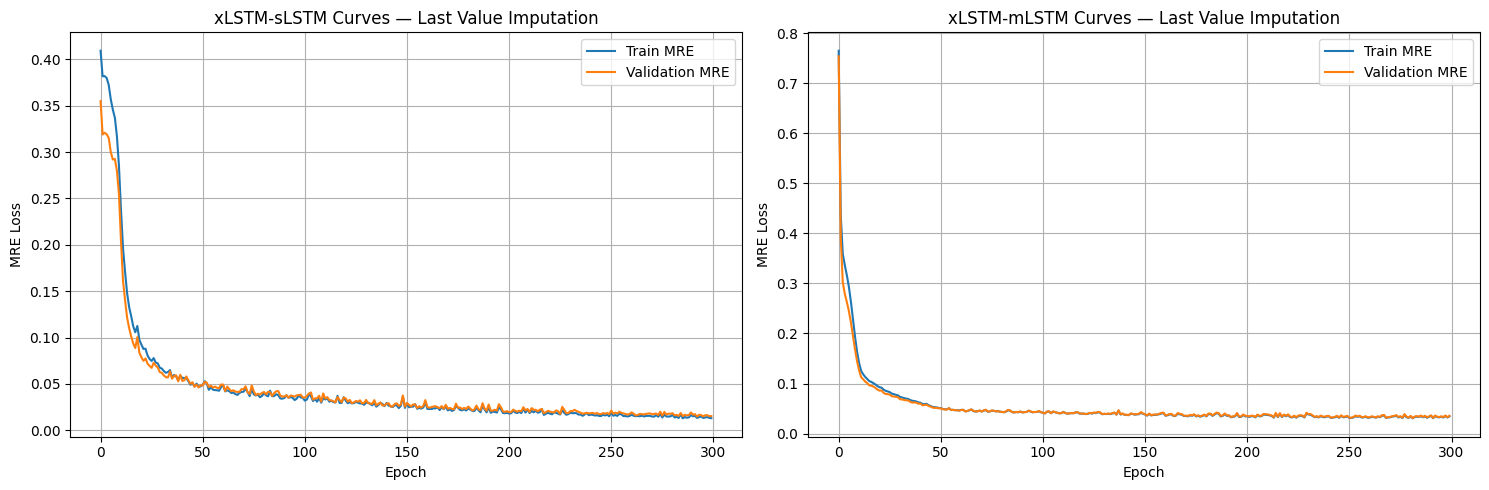

In [100]:
# PLOT TRAINING CURVES

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, xlstm_type in zip(axes, xlstm_types):
    ax.plot(idea1b_errors[xlstm_type]['train'], label='Train MRE')
    ax.plot(idea1b_errors[xlstm_type]['valid'], label='Validation MRE')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MRE Loss')
    ax.set_title(f'xLSTM-{xlstm_type} Curves — Last Value Imputation')
    ax.legend()
    ax.grid()
plt.tight_layout()
plt.show()


In [101]:
tshred.freeze()

UVtest_hat_grud = tshred(test_data_in).to(torch.float64)

Utest_hat = UVtest_hat_grud[:, :POD_modes] @ V1_POD[:POD_modes, :]
Utest_hat = Utest_hat.reshape(test_size, ntimes, nx, ny)
Utest = U_test.reshape(test_size, ntimes, nx, ny)

Vtest_hat = UVtest_hat_grud[:, POD_modes:] @ V2_POD[:POD_modes, :]
Vtest_hat = Vtest_hat.reshape(test_size, ntimes, nx, ny)
Vtest = V_test.reshape(test_size, ntimes, nx, ny)

def plot_tshred_lv_reconstruction(which_test_trajectory, which_time):
    offset = 0.1

    fig, axes = plt.subplots(1, 2, figsize=(20, 5))

    for ax, field_u, field_v, title in zip(
        axes,
        [Utest[which_test_trajectory, which_time],     Utest_hat[which_test_trajectory, which_time]],
        [Vtest[which_test_trajectory, which_time],     Vtest_hat[which_test_trajectory, which_time]],
        [f'Test case {which_test_trajectory} at t = {round(t[which_time], 3)}',
         f'xLSTM-mLSTM (Last Value) reconstruction at t = {round(t[which_time], 3)}']
    ):
        ax.contourf(x, y, vorticity(field_u, field_v).T, cmap='seismic', levels=100)
        ax.streamplot(x, y, field_u.T, field_v.T, color='black', linewidth=1, density=1)
        ax.axis('off')
        ax.axis([0 - offset, Lx + offset, 0 - offset, Ly + offset])
        ax.set_title(title)
        ax.add_patch(patches.Rectangle((0, 0), Lx, Ly, linewidth=5, edgecolor='black', facecolor='none'))
        for k in range(nsensors):
            ax.plot(
                sensors_coordinates[0, k], sensors_coordinates[1, k],
                'o', mfc='magenta', mec='black', ms=12, mew=2.0,
                label='Sensor' if k == 0 else None
            )
        ax.legend(loc='upper right', frameon=True)

    plt.tight_layout()
    plt.show()

interact(
    plot_tshred_lv_reconstruction,
    which_test_trajectory=IntSlider(value=0, min=0, max=test_size - 1, description='Test case'),
    which_time=IntSlider(min=0, max=ntimes - 1, step=1, description='Time step')
);

interactive(children=(IntSlider(value=0, description='Test case', max=9), IntSlider(value=0, description='Time…

In [102]:
## COMPUTE TEST ERRORS FOR BOTH xLSTM VARIANTS

Utest_flat = U_test.reshape(test_size * ntimes, -1).to(torch.float64)
Vtest_flat = V_test.reshape(test_size * ntimes, -1).to(torch.float64)

for xlstm_type in xlstm_types:
    idea1b_models[xlstm_type].freeze()
    UVtest_hat = idea1b_models[xlstm_type](test_data_in).to(torch.float64)

    Utest_hat_flat = (UVtest_hat[:, :POD_modes] @ V1_POD[:POD_modes, :]).reshape(test_size * ntimes, -1)
    Vtest_hat_flat = (UVtest_hat[:, POD_modes:] @ V2_POD[:POD_modes, :]).reshape(test_size * ntimes, -1)

    combined_rmse = (rmse(Utest_flat, Utest_hat_flat) + rmse(Vtest_flat, Vtest_hat_flat)) / 2
    combined_mae  = (mae(Utest_flat,  Utest_hat_flat) + mae(Vtest_flat,  Vtest_hat_flat)) / 2
    combined_mre  = (mre(Utest_flat,  Utest_hat_flat) + mre(Vtest_flat,  Vtest_hat_flat)) / 2

    best_epoch = idea1b_errors[xlstm_type]['valid'].argmin()
    ERRORS.append({
        'model':     f'(xL-{xlstm_type}) Last value imputation',
        'train-mre': num2p(idea1b_errors[xlstm_type]['train'][best_epoch]),
        'val-mre':   num2p(idea1b_errors[xlstm_type]['valid'][best_epoch]),
        'test-mre':  num2p(combined_mre),
        'test-rmse': num2n(combined_rmse),
        'test-mae':  num2n(combined_mae),
    })


In [103]:
dataframe_errors = pd.DataFrame(ERRORS)
print(dataframe_errors)


                               model train-mre  val-mre test-mre test-rmse  \
0  (xL-sLSTM) Only available sensors    8.995%   8.860%  10.921%    1.0239   
1  (xL-mLSTM) Only available sensors   34.277%  27.706%  23.897%    1.6898   
2       (xL-sLSTM) Median imputation    1.598%   1.669%   1.740%    0.1312   
3       (xL-mLSTM) Median imputation    8.225%   7.483%   5.736%    0.4903   
4   (xL-sLSTM) Last value imputation    1.337%   1.487%   1.501%    0.1273   
5   (xL-mLSTM) Last value imputation    3.046%   3.092%   2.692%    0.3118   

  test-mae  
0   0.0130  
1   0.0284  
2   0.0020  
3   0.0068  
4   0.0017  
5   0.0032  


## **Idea 2.A: Masked MHSA**

One masking signal is passed to the model:

 **Implicit mask** — availability flags appended to the input features so the model always knows which readings are real:

mask_train         = ~torch.isnan(input_train)                               # (B, T, S)

masked_input_train = torch.cat([filled_train, mask_train.float()], dim=-1)   # (B, T, 2·S)


 **Dataset**: (X,Y)

train_dataset = MaskedTimeSeriesDataset(train_data_in, train_data_out)



In [104]:

interact(
    plot_train_data_availability,
    trajectory=IntSlider(min=0, max=sensors_data.shape[0] - 1, step=1, value=0, description="Trajectory"),
);

interactive(children=(IntSlider(value=0, description='Trajectory', max=99), Output()), _dom_classes=('widget-i…

In [105]:
# AVAILABILITY MASKS
# True  = sensor value is present (valid)
# False = sensor value is NaN     (missing)

mask_train = ~torch.isnan(input_train)   # (train_size, ntimes, nsensors)
mask_val   = ~torch.isnan(input_val)     # (val_size,   ntimes, nsensors)
mask_test  = ~torch.isnan(input_test)    # (test_size,  ntimes, nsensors)

print(f"mask_train shape: {mask_train.shape}")
print(f"Missing values in train: {(~mask_train).sum().item()} on {mask_train.numel()}")


mask_train shape: torch.Size([80, 101, 3])
Missing values in train: 4730 on 24240


In [106]:
# ZERO-FILL NaN VALUES AND AUGMENT WITH AVAILABILITY FLAGS
#
# Strategy: replace each NaN with 0, then concatenate a binary flag channel
# so the model always knows which sensor readings are real.
# Input feature dim doubles: (batch, time, nsensors) → (batch, time, 2*nsensors)
#
# The first  nsensors columns hold the (zero-filled) sensor readings.
# The second nsensors columns hold the availability flags (1 = present, 0 = missing).

# In this way, the model can learn to ignore the zero-filled values and rely on the flags to identify valid data.

filled_train = input_train.nan_to_num(0.0)
filled_val   = input_val.nan_to_num(0.0)
filled_test  = input_test.nan_to_num(0.0)

masked_input_train = torch.cat([filled_train, mask_train.float()], dim=-1)  # (train_size, ntimes, 2*nsensors)
masked_input_val   = torch.cat([filled_val,   mask_val.float()],   dim=-1)
masked_input_test  = torch.cat([filled_test,  mask_test.float()],  dim=-1)

print(f"Augmented input shape: {masked_input_train.shape}")


Augmented input shape: torch.Size([80, 101, 6])


In [107]:
# BUILD TRAIN, VALIDATION AND TEST DATASETS

device = torch.device("cuda" if torch.cuda.is_available() else "cpu")
print(f"Using device: {device}")

lag = 25

# Padded sensor windows (augmented: zero-filled values + availability flags)
train_data_in = Padding(masked_input_train, lag).to(device)   # (train_size*ntimes, lag, 2*nsensors)
valid_data_in = Padding(masked_input_val,   lag).to(device)
test_data_in  = Padding(masked_input_test,  lag).to(device)

# Targets (unchanged)
train_data_out = Padding(torch.cat((U_train_proj, V_train_proj), 2), 1).squeeze(1).to(device)
valid_data_out = Padding(torch.cat((U_val_proj,   V_val_proj),   2), 1).squeeze(1).to(device)
test_data_out  = Padding(torch.cat((U_test_proj,  V_test_proj),  2), 1).squeeze(1).to(device)

# MaskedTimeSeriesDataset returns (X, key_mask, Y) batches
train_dataset = TimeSeriesDataset(train_data_in, train_data_out)
valid_dataset = TimeSeriesDataset(valid_data_in, valid_data_out)
test_dataset  = TimeSeriesDataset(test_data_in,  test_data_out)

print(f"Train:      {train_data_in.shape}  →  {train_data_out.shape}")
print(f"Validation: {valid_data_in.shape}  →  {valid_data_out.shape}")
print(f"Test:       {test_data_in.shape}   →  {test_data_out.shape}")


Using device: cpu
Train:      torch.Size([8080, 25, 6])  →  torch.Size([8080, 8])
Validation: torch.Size([1010, 25, 6])  →  torch.Size([1010, 8])
Test:       torch.Size([1010, 25, 6])   →  torch.Size([1010, 8])


In [108]:
idea2a_models = {}
idea2a_errors = {}

for xlstm_type in xlstm_types:
    model_args = dict(
        # Encoder
        encoder         = "xlstm",
        encoder_depth   = 1,
        input_size      = 2 * nsensors,         # zero-filled values + availability flags
        hidden_size     = 32,
        xlstm_type      = xlstm_type,

        # Decoder
        decoder         = "cnn",
        decoder_depth   = 1,
        output_size     = 2 * POD_modes,        # U + V POD coefficients

        # Shared
        dropout         = 0.0,
        device          = device,
    )
    idea2a_models[xlstm_type] = TSHRED(args=model_args)

    print(f"\nTraining xLSTM-{xlstm_type} — Implicit Masked...")
    tr_err, val_err = fit(
        idea2a_models[xlstm_type], train_dataset, valid_dataset,
        batch_size=64, epochs=300, lr=1e-3, verbose=True, patience=40
    )
    idea2a_errors[xlstm_type] = {'train': tr_err, 'valid': val_err}

# Use mLSTM as default for reconstruction
tshred       = idea2a_models['mLSTM']
train_errors = idea2a_errors['mLSTM']['train']
valid_errors = idea2a_errors['mLSTM']['valid']



Training xLSTM-sLSTM — Implicit Masked...


Training: 100%|██████████| 300/300 [06:35<00:00,  1.32s/it, Train Error=0.649%, Val Error=0.753%, Patience=4, Best Val Error=0.734%, LR=5.00e-04]  


Training Complete (300 epochs)

Training xLSTM-mLSTM — Implicit Masked...


Training: 100%|██████████| 300/300 [17:43<00:00,  3.54s/it, Train Error=2.614%, Val Error=2.747%, Patience=1, Best Val Error=2.529%, LR=1.00e-03]  

Training Complete (300 epochs)


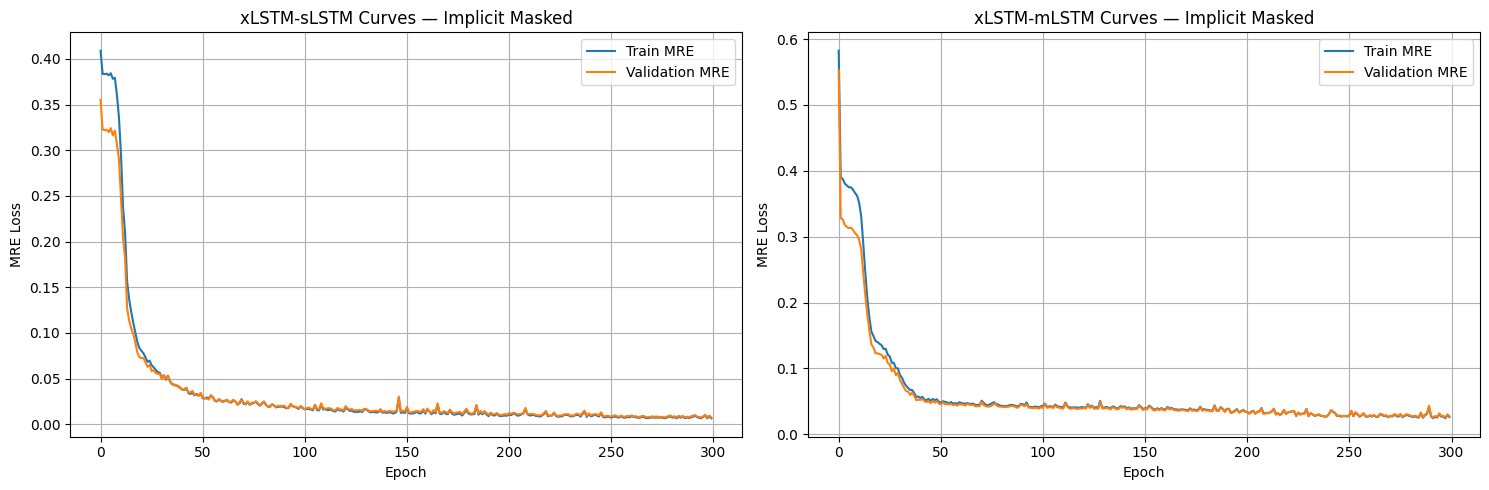

In [109]:
# PLOT TRAINING CURVES

fig, axes = plt.subplots(1, 2, figsize=(15, 5))
for ax, xlstm_type in zip(axes, xlstm_types):
    ax.plot(idea2a_errors[xlstm_type]['train'], label='Train MRE')
    ax.plot(idea2a_errors[xlstm_type]['valid'], label='Validation MRE')
    ax.set_xlabel('Epoch')
    ax.set_ylabel('MRE Loss')
    ax.set_title(f'xLSTM-{xlstm_type} Curves — Implicit Masked')
    ax.legend()
    ax.grid()
plt.tight_layout()
plt.show()


In [110]:
tshred.freeze()

UVtest_hat = tshred(test_data_in).to(torch.float64)

Utest_hat = UVtest_hat[:, :POD_modes] @ V1_POD[:POD_modes, :]
Utest_hat = Utest_hat.reshape(test_size, ntimes, nx, ny)
Utest = U_test.reshape(test_size, ntimes, nx, ny)

Vtest_hat = UVtest_hat[:, POD_modes:] @ V2_POD[:POD_modes, :]
Vtest_hat = Vtest_hat.reshape(test_size, ntimes, nx, ny)
Vtest = V_test.reshape(test_size, ntimes, nx, ny)

def plot_tshred_masked_reconstruction(which_test_trajectory, which_time):
    offset = 0.1

    fig, axes = plt.subplots(1, 2, figsize=(20, 5))

    for ax, field_u, field_v, title in zip(
        axes,
        [Utest[which_test_trajectory, which_time],     Utest_hat[which_test_trajectory, which_time]],
        [Vtest[which_test_trajectory, which_time],     Vtest_hat[which_test_trajectory, which_time]],
        [f'Test case {which_test_trajectory} at t = {round(t[which_time], 3)}',
         f'TSHRED (Masked MHSA) reconstruction at t = {round(t[which_time], 3)}']
    ):
        ax.contourf(x, y, vorticity(field_u, field_v).T, cmap='seismic', levels=100)
        ax.streamplot(x, y, field_u.T, field_v.T, color='black', linewidth=1, density=1)
        ax.axis('off')
        ax.axis([0 - offset, Lx + offset, 0 - offset, Ly + offset])
        ax.set_title(title)
        ax.add_patch(patches.Rectangle((0, 0), Lx, Ly, linewidth=5, edgecolor='black', facecolor='none'))
        for k in range(nsensors):
            ax.plot(
                sensors_coordinates[0, k], sensors_coordinates[1, k],
                'o', mfc='magenta', mec='black', ms=12, mew=2.0,
                label='Sensor' if k == 0 else None
            )
        ax.legend(loc='upper right', frameon=True)

    plt.tight_layout()
    plt.show()

interact(
    plot_tshred_masked_reconstruction,
    which_test_trajectory=IntSlider(value=0, min=0, max=test_size - 1, description='Test case'),
    which_time=IntSlider(min=0, max=ntimes - 1, step=1, description='Time step')
);


interactive(children=(IntSlider(value=0, description='Test case', max=9), IntSlider(value=0, description='Time…

In [111]:
## COMPUTE TEST ERRORS FOR BOTH xLSTM VARIANTS

Utest_flat = U_test.reshape(test_size * ntimes, -1).to(torch.float64)
Vtest_flat = V_test.reshape(test_size * ntimes, -1).to(torch.float64)

for xlstm_type in xlstm_types:
    idea2a_models[xlstm_type].freeze()
    UVtest_hat = idea2a_models[xlstm_type](test_data_in).to(torch.float64)

    Utest_hat_flat = (UVtest_hat[:, :POD_modes] @ V1_POD[:POD_modes, :]).reshape(test_size * ntimes, -1)
    Vtest_hat_flat = (UVtest_hat[:, POD_modes:] @ V2_POD[:POD_modes, :]).reshape(test_size * ntimes, -1)

    combined_rmse = (rmse(Utest_flat, Utest_hat_flat) + rmse(Vtest_flat, Vtest_hat_flat)) / 2
    combined_mae  = (mae(Utest_flat,  Utest_hat_flat) + mae(Vtest_flat,  Vtest_hat_flat)) / 2
    combined_mre  = (mre(Utest_flat,  Utest_hat_flat) + mre(Vtest_flat,  Vtest_hat_flat)) / 2

    best_epoch = idea2a_errors[xlstm_type]['valid'].argmin()
    ERRORS.append({
        'model':     f'(xL-{xlstm_type}) Implicit Masked',
        'train-mre': num2p(idea2a_errors[xlstm_type]['train'][best_epoch]),
        'val-mre':   num2p(idea2a_errors[xlstm_type]['valid'][best_epoch]),
        'test-mre':  num2p(combined_mre),
        'test-rmse': num2n(combined_rmse),
        'test-mae':  num2n(combined_mae),
    })


In [112]:
dataframe_errors = pd.DataFrame(ERRORS)
print(dataframe_errors)


                               model train-mre  val-mre test-mre test-rmse  \
0  (xL-sLSTM) Only available sensors    8.995%   8.860%  10.921%    1.0239   
1  (xL-mLSTM) Only available sensors   34.277%  27.706%  23.897%    1.6898   
2       (xL-sLSTM) Median imputation    1.598%   1.669%   1.740%    0.1312   
3       (xL-mLSTM) Median imputation    8.225%   7.483%   5.736%    0.4903   
4   (xL-sLSTM) Last value imputation    1.337%   1.487%   1.501%    0.1273   
5   (xL-mLSTM) Last value imputation    3.046%   3.092%   2.692%    0.3118   
6         (xL-sLSTM) Implicit Masked    0.655%   0.734%   0.644%    0.0610   
7         (xL-mLSTM) Implicit Masked    2.423%   2.529%   1.999%    0.2687   

  test-mae  
0   0.0130  
1   0.0284  
2   0.0020  
3   0.0068  
4   0.0017  
5   0.0032  
6   0.0007  
7   0.0023  


## Results

In [113]:
dataframe_errors = pd.DataFrame(ERRORS)
print(dataframe_errors)

                               model train-mre  val-mre test-mre test-rmse  \
0  (xL-sLSTM) Only available sensors    8.995%   8.860%  10.921%    1.0239   
1  (xL-mLSTM) Only available sensors   34.277%  27.706%  23.897%    1.6898   
2       (xL-sLSTM) Median imputation    1.598%   1.669%   1.740%    0.1312   
3       (xL-mLSTM) Median imputation    8.225%   7.483%   5.736%    0.4903   
4   (xL-sLSTM) Last value imputation    1.337%   1.487%   1.501%    0.1273   
5   (xL-mLSTM) Last value imputation    3.046%   3.092%   2.692%    0.3118   
6         (xL-sLSTM) Implicit Masked    0.655%   0.734%   0.644%    0.0610   
7         (xL-mLSTM) Implicit Masked    2.423%   2.529%   1.999%    0.2687   

  test-mae  
0   0.0130  
1   0.0284  
2   0.0020  
3   0.0068  
4   0.0017  
5   0.0032  
6   0.0007  
7   0.0023  


In [ ]:
#old run
dataframe_errors = pd.DataFrame(ERRORS)
print(dataframe_errors)

                               model train-mre  val-mre test-mre test-rmse  \
0  (xL-sLSTM) Only available sensors    8.549%  13.336%   7.675%    0.5668   
1  (xL-mLSTM) Only available sensors   32.726%  34.491%  30.247%    2.1253   
2       (xL-sLSTM) Median imputation    1.660%   2.016%   2.056%    0.1470   
3       (xL-mLSTM) Median imputation    8.784%   8.922%   8.992%    0.8056   
4   (xL-sLSTM) Last value imputation    1.939%   2.271%   2.324%    0.1756   
5   (xL-mLSTM) Last value imputation    3.942%   4.354%   4.450%    0.5741   
6         (xL-sLSTM) Implicit Masked    0.591%   0.813%   0.943%    0.0849   
7         (xL-mLSTM) Implicit Masked    3.116%   3.541%   3.612%    0.4764   

  test-mae  
0   0.0090  
1   0.0363  
2   0.0024  
3   0.0107  
4   0.0027  
5   0.0053  
6   0.0011  
7   0.0043  
